In [1]:
RANDOM_STATE = 42
%matplotlib inline
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "data/raw").exists() else Path.cwd().parent
assert (ROOT / "data/raw/application_record.csv").exists(), "Extraia o pacote completo antes de executar."
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from common import load, prepare, FEATURES, preprocessing
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)
OUT = ROOT / "data/processed"
OUT.mkdir(parents=True, exist_ok=True)
RESULTS = ROOT / "docs/resultados"
RESULTS.mkdir(parents=True, exist_ok=True)

# 04 — Avaliação e interpretação
O modelo e o limiar já foram congelados usando apenas treino.

In [2]:
import json,joblib
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,confusion_matrix,ConfusionMatrixDisplay,RocCurveDisplay,PrecisionRecallDisplay
from sklearn.inspection import permutation_importance
d=pd.read_csv(OUT/'dataset_tratado.csv');part=pd.read_csv(OUT/'particoes.csv')
s= json.loads((RESULTS/'selecao.json').read_text())
test=d.merge(part,on='ID',validate='one_to_one').query("particao == 'teste'")
Xt,yt=test[FEATURES],test.TARGET
rows=[]
for name in ['baseline','logistica','floresta']:
    model=joblib.load(OUT/(name+'.joblib'))
    proba=model.predict_proba(Xt)[:,1]
    th=s['limiar'] if name==s['modelo'] else .5
    pred=(proba>=th).astype(int)
    rows.append({'modelo':name,'limiar':th,'acuracia':accuracy_score(yt,pred),'precisao':precision_score(yt,pred,zero_division=0),'recall':recall_score(yt,pred),'f1':f1_score(yt,pred),'roc_auc':roc_auc_score(yt,proba),'ap':average_precision_score(yt,proba)})
metrics=pd.DataFrame(rows);metrics.to_csv(RESULTS/'metricas_teste.csv',index=False);display(metrics)
model=joblib.load(OUT/(s['modelo']+'.joblib'))
proba=model.predict_proba(Xt)[:,1];pred=(proba>=s['limiar']).astype(int)

,modelo,limiar,acuracia,precisao,recall,f1,roc_auc,ap
0,baseline,0.500000,0.882531,0.000000,0.000000,0.000000,0.50000,0.117469
1,logistica,0.433048,0.199587,0.118018,0.898126,0.208622,0.52887,0.140876
2,floresta,0.500000,0.792847,0.113744,0.112412,0.113074,0.49935,0.117076


Acurácia pode ser elevada ao prever todos como negativos. Recall mede quantos atrasos foram detectados; precisão mede quantos alertas correspondem a atrasos. Falso negativo deixa de identificar um histórico com atraso; falso positivo sinaliza um cliente sem atraso 30+ observado. Não há valores de perda ou receita para converter esses erros em custo. As métricas dos candidatos no teste são descritivas e não devem alterar a seleção já feita.

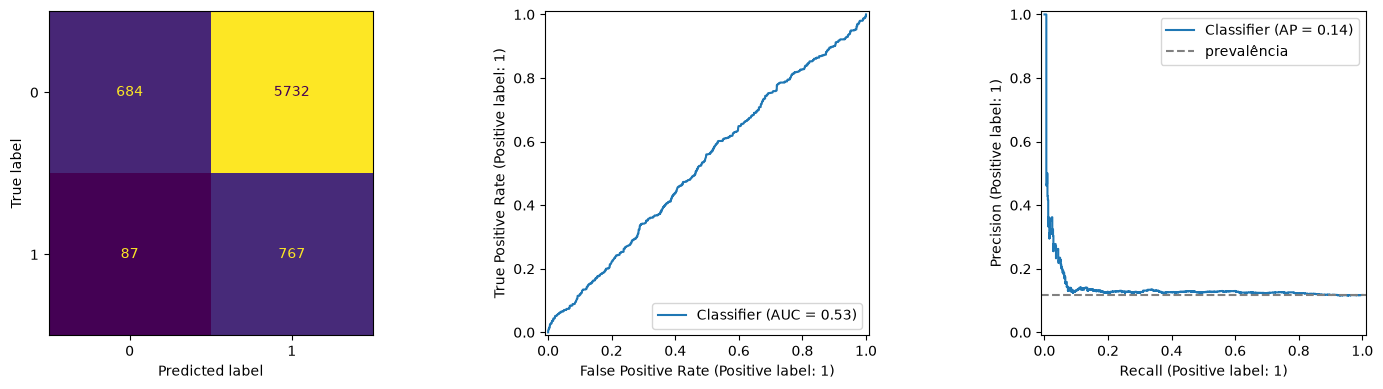

TN=684; FP=5732; FN=87; TP=767. Prevalência=11.747%


In [3]:
fig,ax=plt.subplots(1,3,figsize=(15,4))
ConfusionMatrixDisplay.from_predictions(yt,pred,ax=ax[0],colorbar=False)
RocCurveDisplay.from_predictions(yt,proba,ax=ax[1])
PrecisionRecallDisplay.from_predictions(yt,proba,ax=ax[2])
ax[2].axhline(yt.mean(),ls='--',color='gray',label='prevalência');ax[2].legend()
plt.tight_layout();plt.savefig(RESULTS/'avaliacao.png',dpi=150);plt.show()
tn,fp,fn,tp=confusion_matrix(yt,pred).ravel()
print(f'TN={tn}; FP={fp}; FN={fn}; TP={tp}. Prevalência={yt.mean():.3%}')

A matriz apresenta a quantidade real de acertos e erros no conjunto reservado. A curva precisão-recall deve ser comparada com a prevalência, indicada pela linha horizontal; melhora pequena sugere ganho limitado. ROC-AUC isolada não garante alertas úteis. As probabilidades de modelos com pesos de classe não foram calibradas e não devem ser apresentadas como risco financeiro absoluto.

,feature,queda_ap,dp
14,ANOS_EMPREGADO,0.016500,0.000252
13,EMPREGO_SENTINELA,0.016251,0.000272
11,CNT_FAM_MEMBERS,0.015305,0.003677
3,NAME_INCOME_TYPE,0.014470,0.001320
16,RENDA_POR_MEMBRO,0.006243,0.005500
10,OCCUPATION_TYPE,0.004977,0.002505
12,IDADE_ANOS,0.002868,0.000833
2,CNT_CHILDREN,0.002416,0.002431
5,NAME_FAMILY_STATUS,0.001996,0.004174
9,FLAG_EMAIL,0.000474,0.000492


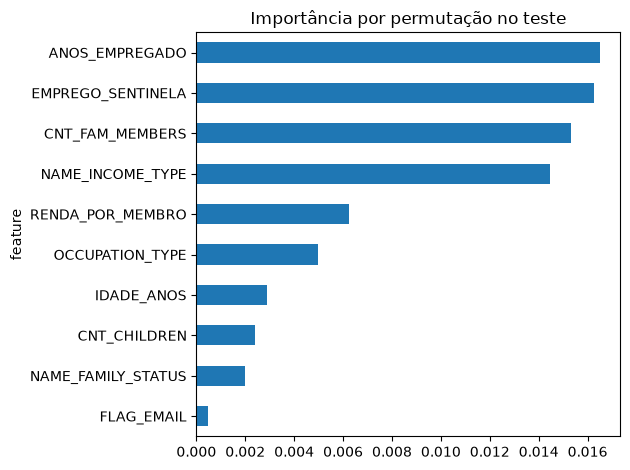

In [4]:
imp=permutation_importance(model,Xt,yt,scoring='average_precision',n_repeats=3,random_state=RANDOM_STATE,n_jobs=1)
importance=pd.DataFrame({'feature':FEATURES,'queda_ap':imp.importances_mean,'dp':imp.importances_std}).sort_values('queda_ap',ascending=False)
importance.to_csv(RESULTS/'importancia.csv',index=False)
display(importance)
importance.head(10).sort_values('queda_ap').plot.barh(x='feature',y='queda_ap',legend=False,title='Importância por permutação no teste');plt.tight_layout();plt.savefig(RESULTS/'importancia.png',dpi=150);plt.show()

A queda de AP estima a contribuição preditiva quando um atributo é embaralhado. Valores próximos de zero ou negativos não demonstram contribuição consistente. Variáveis correlacionadas podem dividir importância; essa análise não explica causalidade e não deve guiar novas escolhas com o mesmo teste.

## Implicações e limitações
A solução apoia o estudo de padrões históricos, mas a capacidade de orientar concessão depende de ganho real sobre baseline, calibração e avaliação em dados posteriores. A amostra contém clientes com cadastro e histórico disponível, não todos os solicitantes nem recusados. O alvo agrega períodos de exposição desiguais; não existe horizonte futuro fixo. Perfis idênticos são agrupados, mas pessoas semelhantes podem continuar em grupos diferentes. Há atributos demográficos e proxies que exigem análise de desempenho por segmento.

Próximos passos: cadastro datado, janela de observação e desfecho de duração fixa, separação temporal, análise de clientes somente X, validação externa, avaliação de segmentos e custos. O resultado acadêmico não demonstra uma política pronta de aprovação.

In [5]:
summary=f"Modelo selecionado: {s['modelo']}; limiar OOF: {s['limiar']:.4f}. Teste: {len(yt)} clientes; {int(yt.sum())} positivos.\n\n"+metrics.to_string(index=False)
# Evita dependência de tabulate: exportação em CSV já é a referência numérica.

In [6]:
(RESULTS/'resumo.txt').write_text(summary)
print(summary)

Modelo selecionado: logistica; limiar OOF: 0.4330. Teste: 7270 clientes; 854 positivos.

   modelo   limiar  acuracia  precisao   recall       f1  roc_auc       ap
 baseline 0.500000  0.882531  0.000000 0.000000 0.000000  0.50000 0.117469
logistica 0.433048  0.199587  0.118018 0.898126 0.208622  0.52887 0.140876
 floresta 0.500000  0.792847  0.113744 0.112412 0.113074  0.49935 0.117076


## Leitura dos resultados desta execução
A logística obteve AUC 0,5289 e AP 0,1409, contra AP baseline 0,1175. No corte 0,4330, recall 89,81% veio com precisão 11,80% e 5.732 falsos positivos. O F1 0,2086 é ligeiramente inferior à referência de prever todos como positivos (0,2102 neste teste). O ganho de discriminação é limitado e não sustenta recusa automática. Emprego, sentinela, tamanho familiar e tipo de renda aparecem como maiores contribuições por permutação, sem demonstrar causalidade. Estes valores documentam a execução salva; se dados ou código mudarem, atualize este texto e o relatório.